In [1]:
import numpy as np
import pandas as pd


# Scarichiamo e leggiamo i dati del train
dataset_file = 'dati/train.csv'
df = pd.read_csv(dataset_file)

# Sostituiamo le stringhe vuote ("") con NaN
df['sii'] = df['sii'].str.strip()
df['PreInt_EduHx-computerinternet_hoursday '] = df['PreInt_EduHx-computerinternet_hoursday '].str.strip()
df['sii'] = df['sii'].replace("", np.nan)
df['PreInt_EduHx-computerinternet_hoursday '] = df['PreInt_EduHx-computerinternet_hoursday '].replace("",np.nan)


# Eliminiamo le righe con valori NaN (vuoti) nella colonna 'sii'
df_clean = df.dropna(subset=['sii', 'PreInt_EduHx-computerinternet_hoursday '])
df_clean.head(10)



,id,Basic_Demos-Enroll_Season,Basic_Demos-Age,Basic_Demos-Sex,CGAS-Season,CGAS-CGAS_Score,Physical-Season,Physical-BMI,Physical-Height,Physical-Weight,...,PCIAT-PCIAT_18,PCIAT-PCIAT_19,PCIAT-PCIAT_20,PCIAT-PCIAT_Total,SDS-Season,SDS-SDS_Total_Raw,SDS-SDS_Total_T,PreInt_EduHx-Season,PreInt_EduHx-computerinternet_hoursday,sii
0,00008ff9,Fall,5,0,Winter,51,Fall,16.87731569,46.0,50.8,...,4,2,4,55,,,,Fall,3,2
1,000fd460,Summer,9,0,,,Fall,14.03559028,48.0,46.0,...,0,0,0,0,Fall,46,64,Summer,0,0
2,00105258,Summer,10,1,Fall,71,Fall,16.64869606,56.5,75.6,...,2,1,1,28,Fall,38,54,Summer,2,0
3,00115b9f,Winter,9,0,Fall,71,Summer,18.29234694,56.0,81.6,...,3,4,1,44,Summer,31,45,Winter,0,1
5,001f3379,Spring,13,1,Winter,50,Summer,22.27995198,59.5,112.2,...,1,2,1,34,Summer,40,56,Spring,0,1
6,0038ba98,Fall,10,0,,,Fall,19.66076033,55.0,84.6,...,4,1,0,20,Winter,27,40,Fall,3,0
11,00abe655,Fall,11,0,Summer,66,,,,,...,0,1,0,10,Winter,42,59,Fall,0,0
12,00ae59c9,Fall,13,0,,,Winter,21.07906523,57.75,100.0,...,2,2,1,31,Fall,33,47,Fall,1,1
15,00c0cd71,Winter,7,0,Summer,51,Spring,29.31577503,54.0,121.6,...,3,3,1,58,Spring,35,50,Winter,2,2
16,00d56d4b,Spring,5,1,Summer,80,Spring,17.28450413,44.0,47.6,...,0,0,0,0,Spring,37,53,Spring,0,0


In [2]:
X = df_clean.loc[:,['Basic_Demos-Age ', 'Basic_Demos-Sex ', 'Physical-BMI ', 'PreInt_EduHx-computerinternet_hoursday ']] # intervallo da id fino alla penultima colonna
X = X.replace(r'^\s*$', np.nan, regex=True)
X = X.astype(float)

print("X shape", X.shape)

y = df_clean.loc[:, 'sii']
print("y shape", y.shape)

X shape (2654, 4)
y shape (2654,)


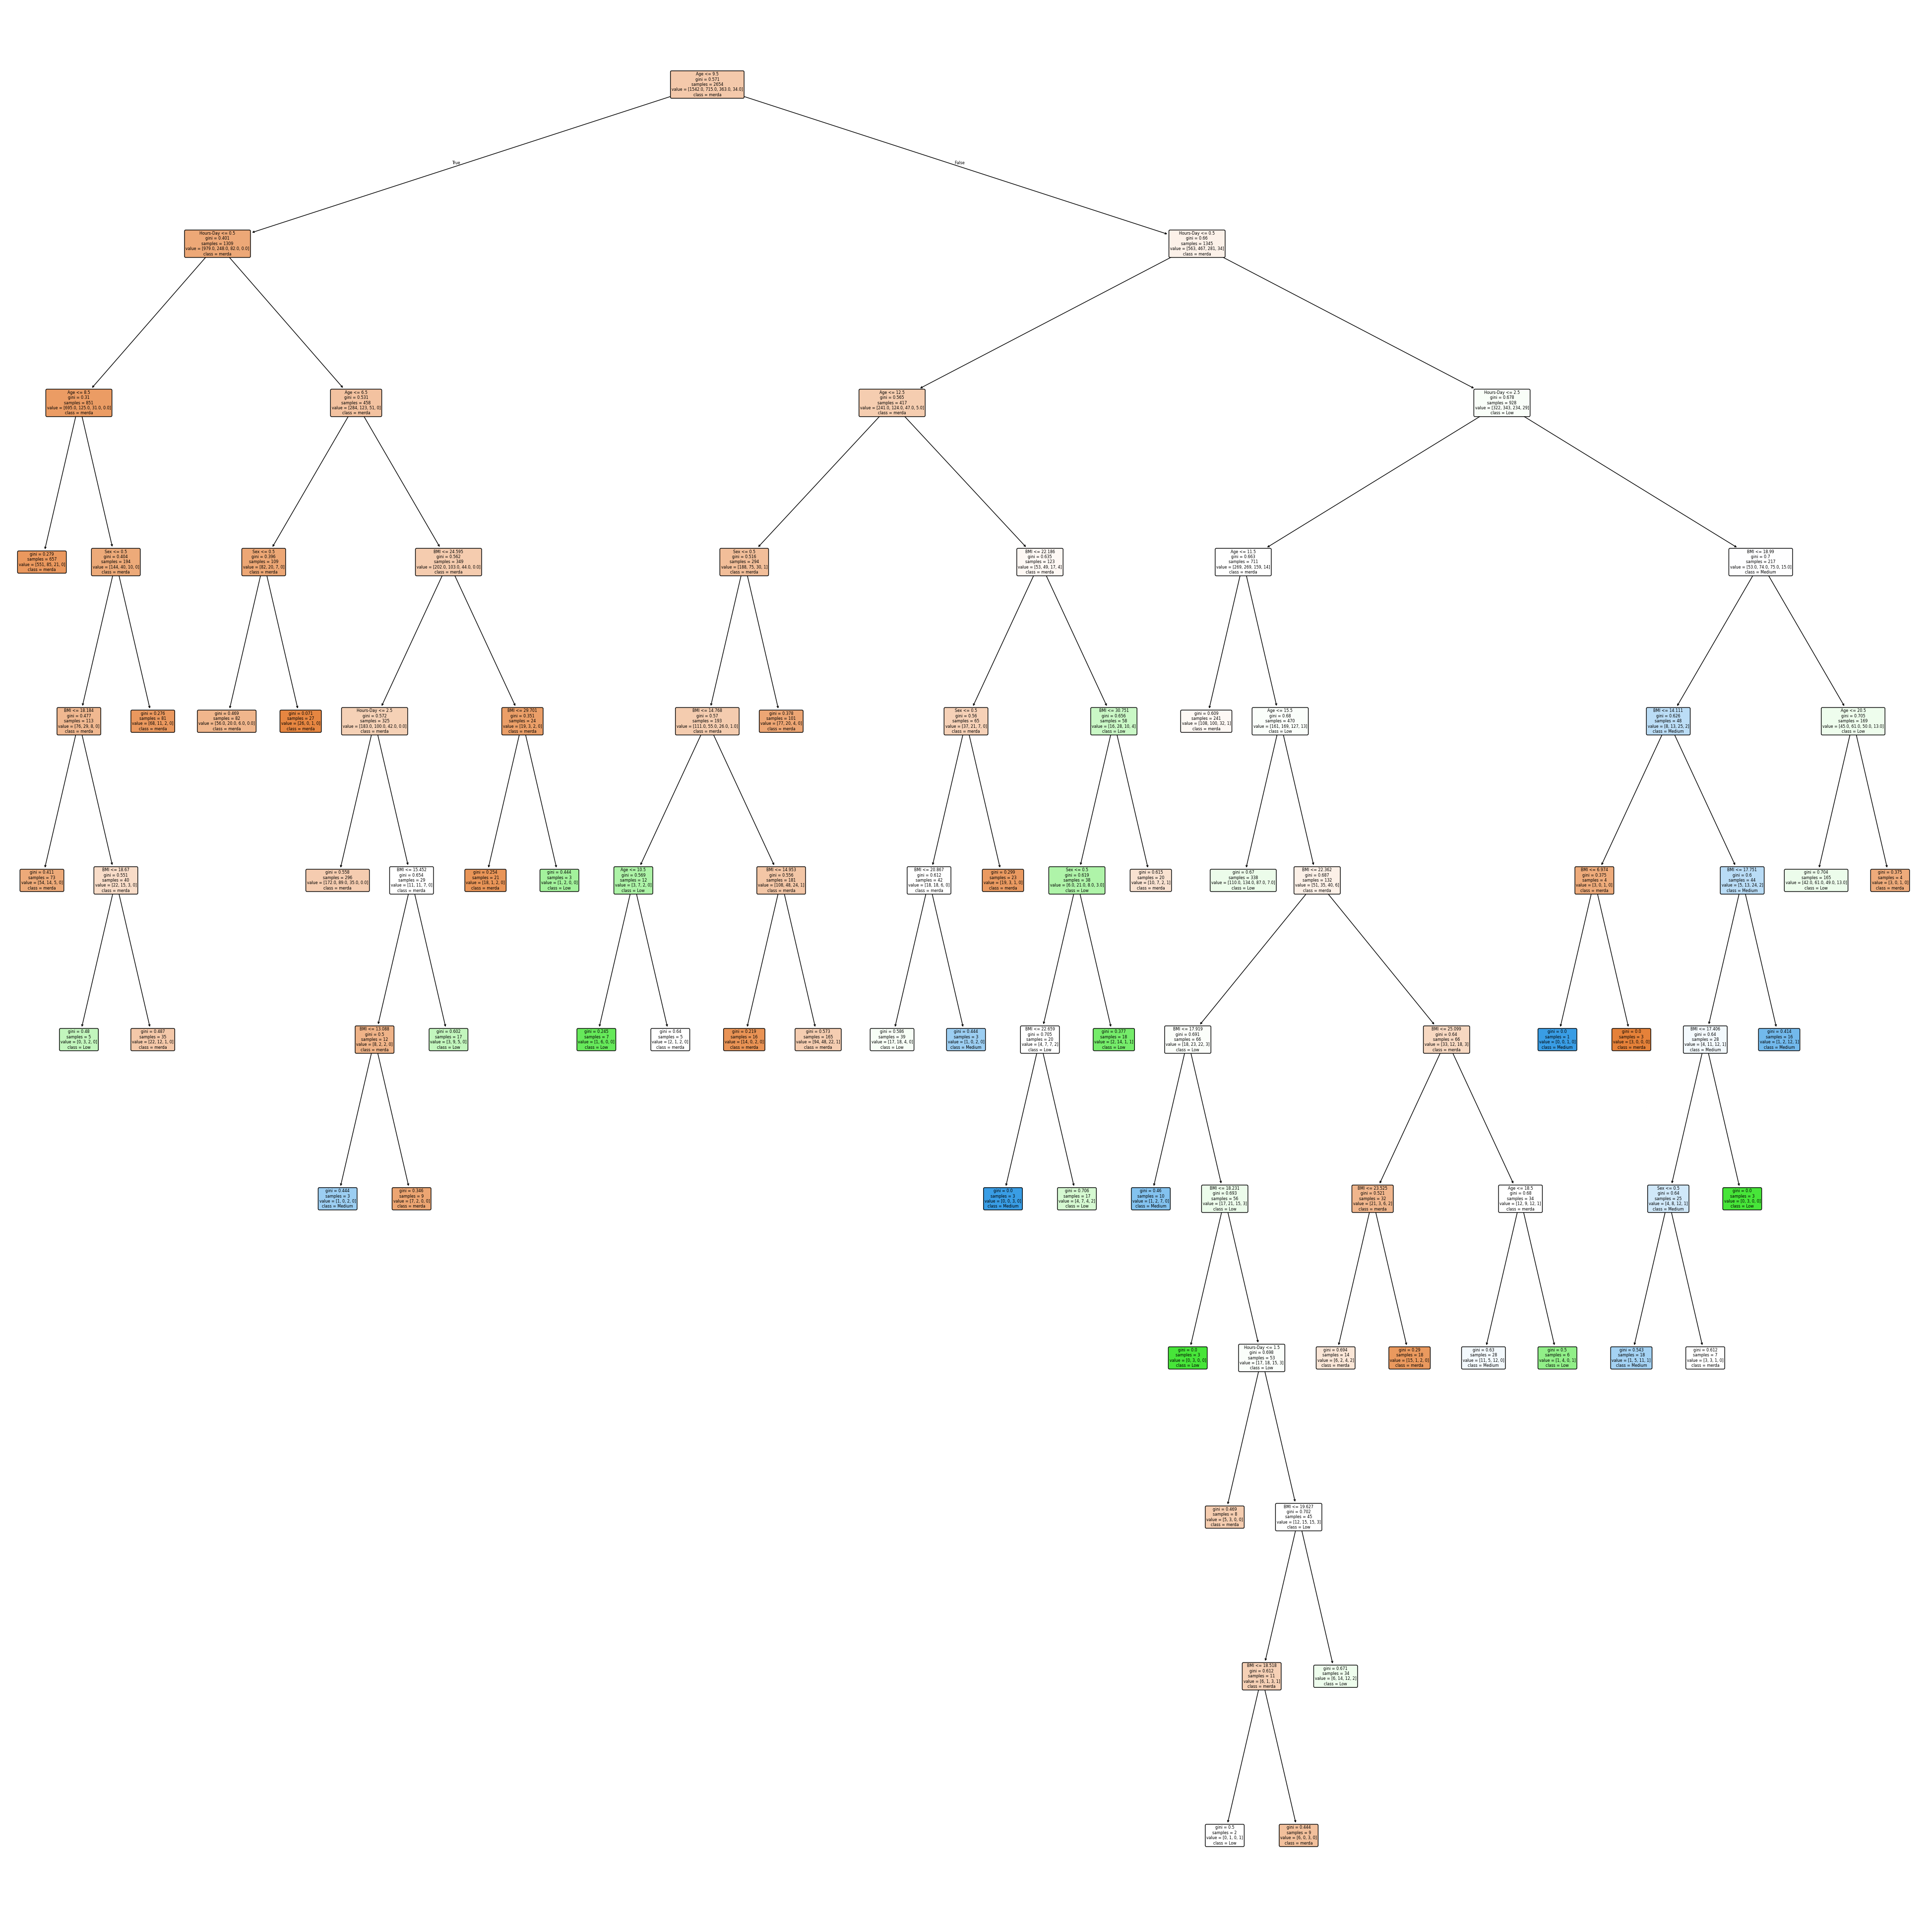

In [5]:
from sklearn.tree import DecisionTreeClassifier
model = DecisionTreeClassifier(max_leaf_nodes=45)
model.fit(X,y)

from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

f_names = ['Age', 'Sex', 'BMI', 'Hours-Day']

c_names = ["merda","Low","Medium","High"]

fig, ax = plt.subplots(figsize=(50, 50))
plot_tree(model, ax=ax,
         feature_names=f_names, class_names=c_names,
                                filled=True, rounded=True);
